In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)

DATA = Path("../data/processed/cleaned_deliveries.csv")
df = pd.read_csv(DATA, dtype={"ball": str, "match_id": str}, low_memory=False)

print("Loaded:", df.shape)
print("Seasons:", int(df["season_year"].min()), "→", int(df["season_year"].max()))
print("Matches:", df["match_id"].nunique(), "| Teams:", df["batting_team"].nunique())

Loaded: (295557, 40)
Seasons: 2008 → 2026
Matches: 1243 | Teams: 15


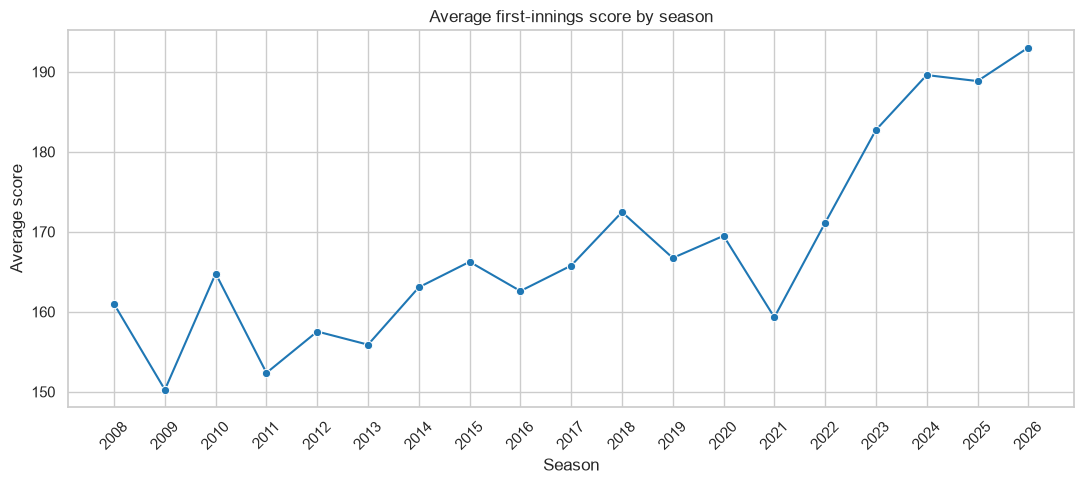

 season_year  avg_score  matches
        2008 160.965517       58
        2009 150.263158       57
        2010 164.783333       60
        2011 152.369863       73
        2012 157.540541       74
        2013 155.894737       76
        2014 163.066667       60
        2015 166.254237       59
        2016 162.600000       60
        2017 165.779661       59
        2018 172.466667       60
        2019 166.733333       60
        2020 169.500000       60
        2021 159.316667       60
        2022 171.121622       74
        2023 182.729730       74
        2024 189.591549       71
        2025 188.837838       74
        2026 193.027027       74


In [3]:
# One row per (match, innings) — total score & wickets
inn = (
    df.groupby(["match_id", "season_year", "innings"], as_index=False)
      .agg(runs=("total_runs", "sum"), wickets=("is_wicket", "sum"))
)

first = inn[inn["innings"] == 1]

season_trend = (
    first.groupby("season_year", as_index=False)
         .agg(avg_score=("runs", "mean"), matches=("match_id", "count"))
)

ax = sns.lineplot(data=season_trend, x="season_year", y="avg_score",
                  marker="o", color="#1f77b4")
ax.set_title("Average first-innings score by season")
ax.set_xlabel("Season")
ax.set_ylabel("Average score")
ax.set_xticks(season_trend["season_year"].unique())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(season_trend.to_string(index=False))

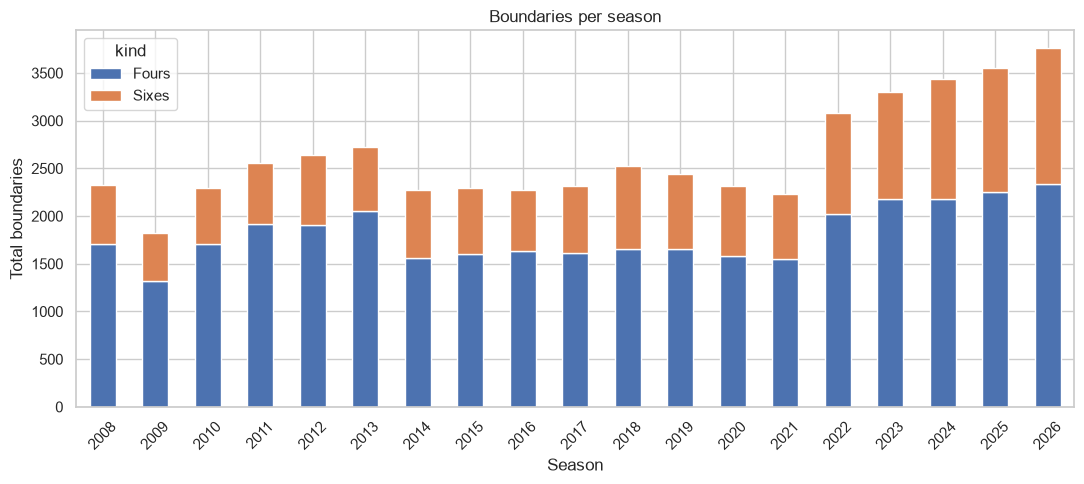

kind         Fours  Sixes
season_year              
2022          2017   1062
2023          2174   1124
2024          2174   1260
2025          2257   1300
2026          2332   1426


In [4]:
# A true boundary: runs_off_bat == 4 or 6 AND non_boundary is not True
boundary = df[
    (df["runs_off_bat"].isin([4, 6])) & (df["non_boundary"] != True)
].copy()
boundary["kind"] = boundary["runs_off_bat"].map({4: "Fours", 6: "Sixes"})

counts = (boundary.groupby(["season_year", "kind"])
                  .size().reset_index(name="count")
                  .pivot(index="season_year", columns="kind", values="count")
                  .fillna(0))

counts.plot(kind="bar", stacked=True, figsize=(11, 5),
            color={"Fours": "#4c72b0", "Sixes": "#dd8452"})
plt.title("Boundaries per season")
plt.ylabel("Total boundaries")
plt.xlabel("Season")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(counts.tail(5).to_string())

In [5]:
# Toss winner vs match winner requires match-level info.
# Build a small match table from the delivery data
matches = df.drop_duplicates("match_id")[["match_id", "season_year",
                                          "batting_team", "bowling_team"]].copy()

# For each match, toss winner is not in deliveries directly.
# We approximate: the team batting first won the toss only if they chose to bat;
# this is a known limitation of the delivery-level CSV — flag for now.
# For the real toss column, we need the _info.csv files.
print("Toss analysis requires the _info.csv files.")
print("Skipping for now — will add in a dedicated step.")

Toss analysis requires the _info.csv files.
Skipping for now — will add in a dedicated step.


In [6]:
from pathlib import Path
import pandas as pd

info_files = sorted(Path("../data/raw").glob("*_info.csv"))
print(f"Found {len(info_files)} _info files")

match_rows = []
for f in info_files:
    match_id = f.stem.replace("_info", "")
    info = pd.read_csv(f, header=None)  # each line is "key,value"
    # Convert list-of-pairs into a dict
    kv = dict(zip(info[0], info[1]))
    # Filter to the fields we want
    row = {
        "match_id": match_id,
        "season":   kv.get("season"),
        "date":     kv.get("date"),
        "venue":    kv.get("venue"),
        "team1":    kv.get("team1"),
        "team2":    kv.get("team2"),
        "toss_winner":   kv.get("toss_winner"),
        "toss_decision": kv.get("toss_decision"),
        "winner":        kv.get("winner"),
        "winner_runs":   kv.get("winner_runs"),
        "winner_wickets":kv.get("winner_wickets"),
    }
    match_rows.append(row)

matches = pd.DataFrame(match_rows)
print("Matches table:", matches.shape)
print(matches.head(3).to_string())

Found 1243 _info files


ParserError: Error tokenizing data. C error: Expected 2 fields in line 2, saw 3


In [7]:
with open("../data/raw/335982_info.csv", encoding="utf-8") as fh:
    for i, line in enumerate(fh):
        if i < 10:
            print(repr(line))

'version,2.4.0\n'
'info,balls_per_over,6\n'
'info,team,Royal Challengers Bangalore\n'
'info,team,Kolkata Knight Riders\n'
'info,team_type,club\n'
'info,gender,male\n'
'info,season,2007/08\n'
'info,date,2008/04/18\n'
'info,event,Indian Premier League\n'
'info,match_id,335982\n'


In [8]:
import csv
from pathlib import Path
import pandas as pd

info_files = sorted(Path("../data/raw").glob("*_info.csv"))
print(f"Found {len(info_files)} _info files")

SINGLE_KEYS = {
    "date", "venue", "city", "season",
    "toss_winner", "toss_decision",
    "winner", "winner_runs", "winner_wickets",
    "player_of_match",
}

match_rows = []
for f in info_files:
    kv = {}
    teams = []
    with open(f, encoding="utf-8", newline="") as fh:
        for row in csv.reader(fh):
            if len(row) < 3 or row[0] != "info":
                continue                     # skips version line + player rows
            key, value = row[1], row[2]
            if key == "team":
                teams.append(value)          # collect both teams
            elif key in SINGLE_KEYS:
                kv[key] = value

    kv["team1"] = teams[0] if len(teams) > 0 else None
    kv["team2"] = teams[1] if len(teams) > 1 else None
    kv["match_id"] = f.stem.replace("_info", "")
    match_rows.append(kv)

matches = pd.DataFrame(match_rows)

for col in ["team1", "team2", "date", "venue", "season",
            "toss_winner", "toss_decision", "winner",
            "winner_runs", "winner_wickets", "player_of_match"]:
    if col not in matches.columns:
        matches[col] = None

matches = matches[["match_id", "season", "date", "venue",
                   "team1", "team2", "toss_winner", "toss_decision",
                   "winner", "winner_runs", "winner_wickets", "player_of_match"]]

print("Matches table:", matches.shape)
print(matches.head(3).to_string())
print("\nNull counts:")
print(matches.isna().sum().to_string())

Found 1243 _info files
Matches table: (1243, 12)
  match_id season        date                                           venue                   team1                        team2                  toss_winner toss_decision                  winner winner_runs winner_wickets player_of_match
0  1082591   2017  2017/04/05       Rajiv Gandhi International Stadium, Uppal     Sunrisers Hyderabad  Royal Challengers Bangalore  Royal Challengers Bangalore         field     Sunrisers Hyderabad          35            NaN    Yuvraj Singh
1  1082592   2017  2017/04/06   Maharashtra Cricket Association Stadium, Pune  Rising Pune Supergiant               Mumbai Indians       Rising Pune Supergiant         field  Rising Pune Supergiant         NaN              7       SPD Smith
2  1082593   2017  2017/04/07  Saurashtra Cricket Association Stadium, Rajkot           Gujarat Lions        Kolkata Knight Riders        Kolkata Knight Riders         field   Kolkata Knight Riders         NaN             10    

In [11]:
matches.to_csv("../data/processed/matches.csv", index=False)
print("Saved: data/processed/matches.csv | shape:", matches.shape)

Saved: data/processed/matches.csv | shape: (1243, 12)


In [12]:
from pathlib import Path
p = Path("../data/processed/matches.csv")
print("Exists:", p.exists(), "| Size (KB):", round(p.stat().st_size / 1024, 1))

Exists: True | Size (KB): 188.7


Matches analysed: 1218
Toss winner also won match: 51.6%

By toss decision:
                   mean  count
toss_decision                 
bat            0.453431    408
field          0.546914    810


C:\Users\pa1ku\AppData\Local\Temp\ipykernel_20068\2462711963.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Lost toss", "Won toss"], y=[1 - rate, rate],
C:\Users\pa1ku\AppData\Local\Temp\ipykernel_20068\2462711963.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=by_dec.index, y=by_dec.values, palette="Blues_d", ax=ax[1])


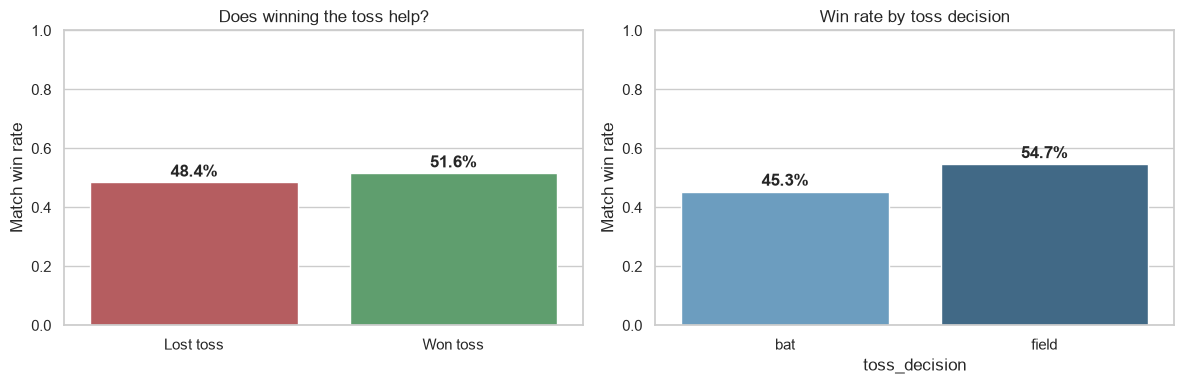

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

m = matches.dropna(subset=["toss_winner", "toss_decision", "winner"]).copy()
m["toss_win_match_win"] = (m["toss_winner"] == m["winner"]).astype(int)

rate = m["toss_win_match_win"].mean()
print(f"Matches analysed: {len(m)}")
print(f"Toss winner also won match: {rate:.1%}")
print()
print("By toss decision:")
print(m.groupby("toss_decision")["toss_win_match_win"]
        .agg(["mean", "count"]).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=["Lost toss", "Won toss"], y=[1 - rate, rate],
            palette=["#c44e52", "#55a868"], ax=ax[0])
ax[0].set_ylim(0, 1)
ax[0].set_ylabel("Match win rate")
ax[0].set_title("Does winning the toss help?")
for i, v in enumerate([1 - rate, rate]):
    ax[0].text(i, v + 0.02, f"{v:.1%}", ha="center", fontweight="bold")

by_dec = m.groupby("toss_decision")["toss_win_match_win"].mean()
sns.barplot(x=by_dec.index, y=by_dec.values, palette="Blues_d", ax=ax[1])
ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Match win rate")
ax[1].set_title("Win rate by toss decision")
for i, v in enumerate(by_dec.values):
    ax[1].text(i, v + 0.02, f"{v:.1%}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [16]:
# Per-innings totals
inn = (
    df.groupby(["match_id", "innings"], as_index=False)
      .agg(runs=("total_runs", "sum"), wickets=("is_wicket", "sum"))
)

# First innings only (for average score)
first_inn = inn[inn["innings"] == 1].merge(
    matches[["match_id", "venue"]], on="match_id", how="left"
)

# Chasing team win rate
second_inn = inn[inn["innings"] == 2].merge(
    matches[["match_id", "venue", "winner"]], on="match_id", how="left"
)
batting_second = (
    df[df["innings"] == 2]
    .drop_duplicates("match_id")[["match_id", "batting_team"]]
)
second_inn = second_inn.merge(batting_second, on="match_id", how="left")
second_inn["chase_won"] = (second_inn["batting_team"] == second_inn["winner"]).astype(int)

venue_profile = (
    first_inn.groupby("venue")
    .agg(matches=("match_id", "count"),
         avg_first_inn=("runs", "mean"))
    .join(
        second_inn.groupby("venue")["chase_won"].mean().rename("chase_win_rate"),
        how="outer"
    )
    .query("matches >= 20")
    .sort_values("matches", ascending=False)
    .round(2)
)

print(venue_profile.to_string())# Per-innings totals
inn = (
    df.groupby(["match_id", "innings"], as_index=False)
      .agg(runs=("total_runs", "sum"), wickets=("is_wicket", "sum"))
)

# First innings only (for average score)
first_inn = inn[inn["innings"] == 1].merge(
    matches[["match_id", "venue"]], on="match_id", how="left"
)

# Chasing team win rate
second_inn = inn[inn["innings"] == 2].merge(
    matches[["match_id", "venue", "winner"]], on="match_id", how="left"
)
batting_second = (
    df[df["innings"] == 2]
    .drop_duplicates("match_id")[["match_id", "batting_team"]]
)
second_inn = second_inn.merge(batting_second, on="match_id", how="left")
second_inn["chase_won"] = (second_inn["batting_team"] == second_inn["winner"]).astype(int)

venue_profile = (
    first_inn.groupby("venue")
    .agg(matches=("match_id", "count"),
         avg_first_inn=("runs", "mean"))
    .join(
        second_inn.groupby("venue")["chase_won"].mean().rename("chase_win_rate"),
        how="outer"
    )
    .query("matches >= 20")
    .sort_values("matches", ascending=False)
    .round(2)
)

print(venue_profile.to_string())

                                                                       matches  avg_first_inn  chase_win_rate
venue                                                                                                        
Wankhede Stadium, Mumbai                                                   132         173.13            0.48
Eden Gardens, Kolkata                                                      107         168.64            0.51
MA Chidambaram Stadium                                                      98         165.56            0.43
Rajiv Gandhi International Stadium, Uppal                                   90         168.34            0.42
Feroz Shah Kotla, Delhi                                                     74         162.89            0.27
Sawai Mansingh Stadium, Jaipur                                              68         169.06            0.60
M Chinnaswamy Stadium, Bengaluru                                            62         180.58            0.39
Dubai Inte

In [17]:
import pandas as pd

# --- Team standardisation (same map as in Module 1) ---
TEAM_MAP = {
    "Delhi Daredevils":            "Delhi Capitals",
    "Kings XI Punjab":             "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants":     "Rising Pune Supergiant",
}
for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(TEAM_MAP)

# --- Venue standardisation ---
def clean_venue(s):
    if pd.isna(s):
        return s
    base = s.split(",")[0].strip()      # drop ", City" suffix
    rename = {
        "Feroz Shah Kotla":                   "Arun Jaitley Stadium",
        "Punjab Cricket Association Stadium": "Punjab Cricket Association IS Bindra Stadium",
        "Sardar Patel Stadium":               "Narendra Modi Stadium",
        "Zayed Cricket Stadium":              "Sheikh Zayed Stadium",
        "M.Chinnaswamy Stadium":              "M Chinnaswamy Stadium",
    }
    return rename.get(base, base)

matches["venue"] = matches["venue"].apply(clean_venue)

# Re-save so the fix persists
matches.to_csv("../data/processed/matches.csv", index=False)

print("Unique teams:", matches["team1"].nunique())
print("Unique venues:", matches["venue"].nunique())
print("Sample venues:", sorted(matches["venue"].unique())[:8])

Unique teams: 15
Unique venues: 37
Sample venues: ['Andhra Cricket Association-Visakhapatnam District Cricket Association Stadium', 'Arun Jaitley Stadium', 'Barabati Stadium', 'Barsapara Cricket Stadium', 'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium', 'Brabourne Stadium', 'Buffalo Park', 'Diamond Oval']


In [18]:
inn = (
    df.groupby(["match_id", "innings"], as_index=False)
      .agg(runs=("total_runs", "sum"), wickets=("is_wicket", "sum"))
)

first_inn = inn[inn["innings"] == 1].merge(
    matches[["match_id", "venue"]], on="match_id", how="left"
)

# Only completed matches (drop the 25 abandoned)
second_inn = inn[inn["innings"] == 2].merge(
    matches[["match_id", "venue", "winner"]], on="match_id", how="left"
).dropna(subset=["winner"])

batting_second = (
    df[df["innings"] == 2]
    .drop_duplicates("match_id")[["match_id", "batting_team"]]
)
second_inn = second_inn.merge(batting_second, on="match_id", how="left")
second_inn["chase_won"] = (second_inn["batting_team"] == second_inn["winner"]).astype(int)

venue_profile = (
    first_inn.groupby("venue")
    .agg(matches=("match_id", "count"),
         avg_first_inn=("runs", "mean"))
    .join(
        second_inn.groupby("venue")["chase_won"].mean().rename("chase_win_rate"),
        how="outer"
    )
    .query("matches >= 20")
    .sort_values("matches", ascending=False)
    .round(2)
)

print(venue_profile.to_string())

                                                              matches  avg_first_inn  chase_win_rate
venue                                                                                               
Wankhede Stadium                                                  132         173.13            0.55
Eden Gardens                                                      107         168.64            0.57
M Chinnaswamy Stadium                                             104         174.06            0.56
Arun Jaitley Stadium                                              104         171.76            0.53
MA Chidambaram Stadium                                             98         165.56            0.47
Rajiv Gandhi International Stadium                                 90         168.34            0.55
Sawai Mansingh Stadium                                             68         169.06            0.65
Punjab Cricket Association IS Bindra Stadium                       61         168.28       